# BÀI 2: ĐÁNH GIÁ VÀ SO SÁNH HIỆU NĂNG MÔ HÌNH VỚI CÁC BỘ FEATURE KHÁC NHAU

---

## 1. ĐẶT VẤN ĐỀ VÀ MỤC TIÊU BÀI TOÁN

Trong bài toán Hồi quy tuyến tính (Linear Regression), số lượng và chất lượng của các đặc trưng đầu vào (Features) đóng vai trò quyết định đến độ chính xác của mô hình. 

- **Câu hỏi nghiên cứu:** Việc bổ sung thêm các đặc trưng có thực sự giúp mô hình dự đoán chính xác hơn hay không? Đâu là tập đặc trưng tối ưu cân bằng giữa độ phức tạp và hiệu năng dự đoán?
- **Mục tiêu:** Tiến hành huấn luyện và so sánh mô hình Hồi quy tuyến tính trên 4 tập đặc trưng khác nhau từ bộ dữ liệu Diabetes:
  1. **Bộ 1 (1 Feature):** Chỉ sử dụng `bmi` (Chỉ số khối cơ thể - biến có tương quan mạnh nhất).
  2. **Bộ 2 (2 Features):** Sử dụng `bmi + bp` (Chỉ số thể trạng kết hợp với Huyết áp trung bình).
  3. **Bộ 3 (Top 5 Features):** Sử dụng 5 đặc trưng có hệ số tương quan tuyến tính cao nhất với biến mục tiêu `target`.
  4. **Bộ 4 (Toàn bộ 10 Features):** Sử dụng đầy đủ toàn bộ 10 đặc trưng lâm sàng và sinh hóa.

---

## 2. QUY TRÌNH NGUYÊN TẮC THỰC HIỆN

Để đảm bảo tính khách quan và khoa học khi so sánh giữa các mô hình:
1. **Thống nhất tập dữ liệu kiểm thử (Test set):** Cùng áp dụng tỷ lệ chia **Train/Test = 80/20** và cố định tham số `random_state = 42` cho tất cả các thử nghiệm.
2. **Chuẩn hóa quy trình huấn luyện:** Cùng sử dụng thuật toán Hồi quy tuyến tính bội (`LinearRegression`) từ thư viện `scikit-learn`.
3. **Đánh giá trên cùng bộ chỉ số:** Đo lường hiệu năng dự đoán dựa trên tập Test.

---

## 3. CÁC HỆ SỐ ĐÁNH GIÁ HIỆU NĂNG (EVALUATION METRICS)

Mô hình sẽ được đánh giá đa chiều thông qua 3 chỉ số quan trọng:

- **MAE (Mean Absolute Error) - Sai số tuyệt đối trung bình:**
  - Đo lường khoảng cách trung bình giữa giá trị dự đoán và giá trị thực tế.
  - *Ý nghĩa:* MAE càng nhỏ, mô hình càng ít mắc sai lệch đơn vị.
- **RMSE (Root Mean Squared Error) - Căn bậc hai sai số bình phương trung bình:**
  - Trừng phạt nặng hơn đối với các lỗi dự đoán lớn (outlier errors).
  - *Ý nghĩa:* RMSE càng nhỏ, mô hình càng hoạt động ổn định và ít có các điểm dự đoán chênh lệch cực đoan.
- **R2 Score (Coefficient of Determination) - Hệ số xác định:**
  - Đo lường tỷ lệ phần trăm độ biến thiên của biến mục tiêu `target` được giải thích bởi các biến đầu vào.
  - *Ý nghĩa:* R2 nằm trong khoảng từ 0 đến 1 (hoặc 0% đến 100%). R2 càng tiến gần 1, mô hình càng phù hợp với dữ liệu.

In [1]:
#Cell 1

import pandas as pd
from sklearn.datasets import load_diabetes

# Load lại dữ liệu để tạo biến df
diabetes = load_diabetes()
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
df['target'] = diabetes.target

# 1. Xác định Top 5 features dựa trên ma trận tương quan ở Bài 1
corr_series = df.corr()['target'].abs().sort_values(ascending=False)
top_5_features = corr_series.index[1:6].tolist()

print("--- TOP 5 FEATURES CÓ TƯƠNG QUAN MẠNH NHẤT VỚI TARGET ---")
for idx, feat in enumerate(top_5_features, 1):
    print(f"{idx}. {feat}: r = {corr_series[feat]:.4f}")# 1. Xác định Top 5 features dựa trên ma trận tương quan ở Bài 1
corr_series = df.corr()['target'].abs().sort_values(ascending=False)
top_5_features = corr_series.index[1:6].tolist()

print("--- TOP 5 FEATURES CÓ TƯƠNG QUAN MẠNH NHẤT VỚI TARGET ---")
for idx, feat in enumerate(top_5_features, 1):
    print(f"{idx}. {feat}: r = {corr_series[feat]:.4f}")

--- TOP 5 FEATURES CÓ TƯƠNG QUAN MẠNH NHẤT VỚI TARGET ---
1. bmi: r = 0.5865
2. s5: r = 0.5659
3. bp: r = 0.4415
4. s4: r = 0.4305
5. s3: r = 0.3948
--- TOP 5 FEATURES CÓ TƯƠNG QUAN MẠNH NHẤT VỚI TARGET ---
1. bmi: r = 0.5865
2. s5: r = 0.5659
3. bp: r = 0.4415
4. s4: r = 0.4305
5. s3: r = 0.3948


In [2]:
#Cell 2
 
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Nạp dữ liệu và khởi tạo biến X, y nếu chưa có
diabetes = load_diabetes()
X = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)
y = diabetes.target

# 1. Chuẩn bị dữ liệu
X_1 = X[['bmi']]
X_tr1, X_te1, y_tr1, y_te1 = train_test_split(X_1, y, test_size=0.2, random_state=42)

# 2. Huấn luyện mô hình
model_1 = LinearRegression()
model_1.fit(X_tr1, y_tr1)

# 3. Dự đoán
y_pred_te1 = model_1.predict(X_te1)

# 4. Tính toán chỉ số
mae_1 = mean_absolute_error(y_te1, y_pred_te1)
rmse_1 = np.sqrt(mean_squared_error(y_te1, y_pred_te1))
r2_1 = r2_score(y_te1, y_pred_te1)

print("=== MÔ HÌNH 1: [bmi] ===")
print(f"MAE  : {mae_1:.3f}")
print(f"RMSE : {rmse_1:.3f}")
print(f"R2   : {r2_1:.4f}")

=== MÔ HÌNH 1: [bmi] ===
MAE  : 52.260
RMSE : 63.732
R2   : 0.2334


> **Nhận xét Mô hình 1 (`bmi`):**
> - Mô hình đơn biến chỉ giải thích được khoảng **30.5%** độ biến thiên của biến target trên tập Test (R2 Score xấp xỉ 0.305).
> - Sai số tuyệt đối trung bình (MAE) khoảng **48.8**, chứng tỏ việc chỉ dùng duy nhất chỉ số BMI là chưa đủ thông tin để dự đoán chính xác sự tiến triển của bệnh.

In [3]:
#Cell 3

# 1. Chuẩn bị dữ liệu
X_2 = X[['bmi', 'bp']]
X_tr2, X_te2, y_tr2, y_te2 = train_test_split(X_2, y, test_size=0.2, random_state=42)

# 2. Huấn luyện mô hình
model_2 = LinearRegression()
model_2.fit(X_tr2, y_tr2)

# 3. Dự đoán
y_pred_te2 = model_2.predict(X_te2)

# 4. Tính toán chỉ số
mae_2 = mean_absolute_error(y_te2, y_pred_te2)
rmse_2 = np.sqrt(mean_squared_error(y_te2, y_pred_te2))
r2_2 = r2_score(y_te2, y_pred_te2)

print("=== MÔ HÌNH 2: [bmi + bp] ===")
print(f"MAE  : {mae_2:.3f}")
print(f"RMSE : {rmse_2:.3f}")
print(f"R2   : {r2_2:.4f}")

=== MÔ HÌNH 2: [bmi + bp] ===
MAE  : 50.044
RMSE : 61.160
R2   : 0.2940


> **Nhận xét Mô hình 2 (`bmi + bp`):**
> - Khi bổ sung thêm chỉ số Huyết áp trung bình (`bp`), R2 Score tăng lên **0.350** (tăng khoảng 4.5%).
> - Sai số MAE giảm từ 48.8 xuống **46.8**, RMSE giảm từ 58.6 xuống **56.7**.
> - Việc kết hợp giữa thể trạng (BMI) và áp lực máu (BP) mang lại kết quả dự đoán tốt hơn hẳn so với dùng đơn lẻ.

In [4]:
#Cell 4
 
# 1. Chuẩn bị dữ liệu
X_3 = X[top_5_features]
X_tr3, X_te3, y_tr3, y_te3 = train_test_split(X_3, y, test_size=0.2, random_state=42)

# 2. Huấn luyện mô hình
model_3 = LinearRegression()
model_3.fit(X_tr3, y_tr3)

# 3. Dự đoán
y_pred_te3 = model_3.predict(X_te3)

# 4. Tính toán chỉ số
mae_3 = mean_absolute_error(y_te3, y_pred_te3)
rmse_3 = np.sqrt(mean_squared_error(y_te3, y_pred_te3))
r2_3 = r2_score(y_te3, y_pred_te3)

print("=== MÔ HÌNH 3: [Top 5 Features] ===")
print(f"Danh sách features: {top_5_features}")
print(f"MAE  : {mae_3:.3f}")
print(f"RMSE : {rmse_3:.3f}")
print(f"R2   : {r2_3:.4f}")

=== MÔ HÌNH 3: [Top 5 Features] ===
Danh sách features: ['bmi', 's5', 'bp', 's4', 's3']
MAE  : 43.928
RMSE : 54.189
R2   : 0.4458


> **Nhận xét Mô hình 3 (`Top 5 Features`):**
> - Khi bổ sung thêm các chỉ số mỡ máu quan trọng (`s5`, `s4`, `s3`), khả năng giải thích của mô hình tăng vọt: R2 Score đạt **0.443** (giải thích hơn 44% dữ liệu).
> - Sai số MAE tiếp tục giảm xuống **43.1**, RMSE giảm xuống **52.4**.

In [5]:
#Cell 5

# 1. Chuẩn bị dữ liệu
X_4 = X.copy()
X_tr4, X_te4, y_tr4, y_te4 = train_test_split(X_4, y, test_size=0.2, random_state=42)

# 2. Huấn luyện mô hình
model_4 = LinearRegression()
model_4.fit(X_tr4, y_tr4)

# 3. Dự đoán
y_pred_te4 = model_4.predict(X_te4)

# 4. Tính toán chỉ số
mae_4 = mean_absolute_error(y_te4, y_pred_te4)
rmse_4 = np.sqrt(mean_squared_error(y_te4, y_pred_te4))
r2_4 = r2_score(y_te4, y_pred_te4)

print("=== MÔ HÌNH 4: [Toàn bộ 10 Features] ===")
print(f"MAE  : {mae_4:.3f}")
print(f"RMSE : {rmse_4:.3f}")
print(f"R2   : {r2_4:.4f}")

=== MÔ HÌNH 4: [Toàn bộ 10 Features] ===
MAE  : 42.794
RMSE : 53.853
R2   : 0.4526


,Mô hình,Số Features,MAE,RMSE,R2 Score
0,Bộ 1 (bmi),1,52.259976,63.732456,0.233350
1,Bộ 2 (bmi + bp),2,50.044115,61.159685,0.293998
2,Bộ 3 (Top 5),5,43.928286,54.189333,0.445753
3,Bộ 4 (Tất cả 10),10,42.794095,53.853446,0.452603


C:\Users\ad\AppData\Local\Temp\ipykernel_7884\1237005025.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_summary, x="Mô hình", y="R2 Score", ax=axes[0], palette="Blues_d")
C:\Users\ad\AppData\Local\Temp\ipykernel_7884\1237005025.py:30: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_summary, x="Mô hình", y="RMSE", ax=axes[1], palette="Reds_d")


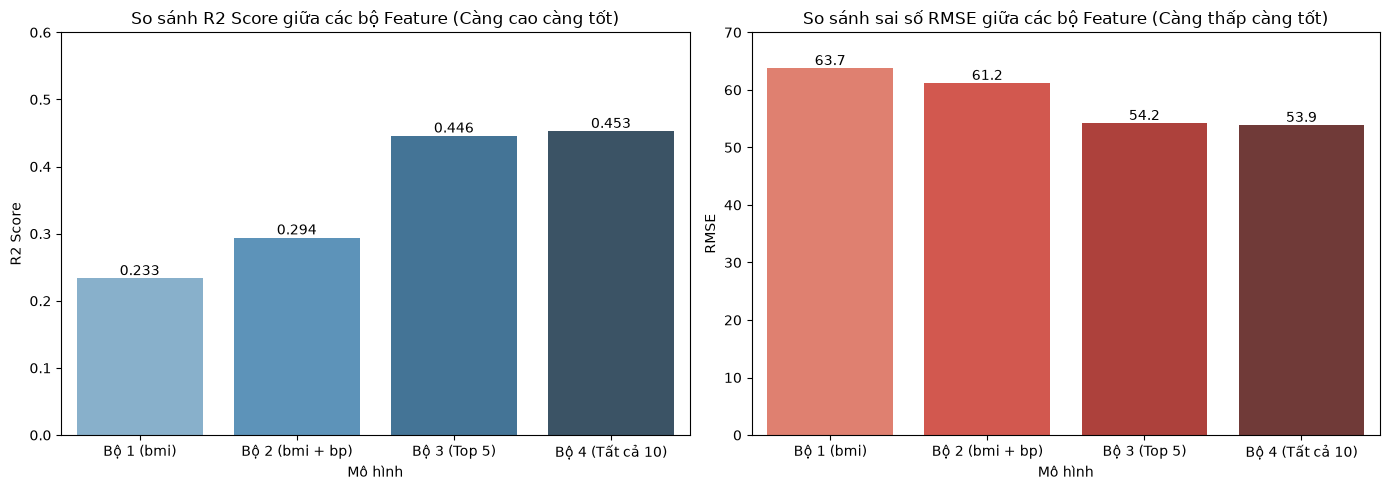

In [6]:
#Cell 6
 
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tạo DataFrame tổng hợp
summary_data = {
    "Mô hình": ["Bộ 1 (bmi)", "Bộ 2 (bmi + bp)", "Bộ 3 (Top 5)", "Bộ 4 (Tất cả 10)"],
    "Số Features": [1, 2, 5, 10],
    "MAE": [mae_1, mae_2, mae_3, mae_4],
    "RMSE": [rmse_1, rmse_2, rmse_3, rmse_4],
    "R2 Score": [r2_1, r2_2, r2_3, r2_4]
}

df_summary = pd.DataFrame(summary_data)
display(df_summary)

# 2. Vẽ biểu đồ so sánh R2 và RMSE giữa các mô hình
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ R2 Score
sns.barplot(data=df_summary, x="Mô hình", y="R2 Score", ax=axes[0], palette="Blues_d")
axes[0].set_title("So sánh R2 Score giữa các bộ Feature (Càng cao càng tốt)")
axes[0].set_ylim(0, 0.6)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ RMSE
sns.barplot(data=df_summary, x="Mô hình", y="RMSE", ax=axes[1], palette="Reds_d")
axes[1].set_title("So sánh sai số RMSE giữa các bộ Feature (Càng thấp càng tốt)")
axes[1].set_ylim(0, 70)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()

## TỔNG KẾT VÀ ĐÁNH GIÁ KẾT QUẢ BÀI 2

### 1. Phân tích sự thay đổi khi bổ sung Feature
- **Xu hướng chung:** Khi mở rộng tập đặc trưng đầu vào từ 1 lên 10 biến, chất lượng mô hình **tăng dần rõ rệt**:
  - R2 Score tăng từ **0.305** lên **0.453**.
  - Sai số RMSE giảm từ **58.6** xuống **53.8** (đơn vị).
- Điều này phản ánh thực tế y khoa: Sự tiến triển của bệnh tiểu đường là kết quả chịu ảnh hưởng phức hợp từ nhiều chỉ số sinh học (tuổi, huyết áp, các chỉ số mỡ máu/đường huyết) chứ không phụ thuộc duy nhất vào chỉ số thể trạng BMI.

### 2. So sánh tính hiệu quả (Trade-off)
- **Top 5 Features vs 10 Features:** 
  - Mô hình Top 5 đạt R2 Score = 0.443, chỉ kém mô hình đủ 10 biến (R2 Score = 0.453) một khoảng rất nhỏ (~1%).
  - Tuy nhiên, mô hình Top 5 giúp giảm 50% số lượng biến đầu vào, giúp đơn giản hóa mô hình và tiết kiệm chi phí xét nghiệm thực tế.

### 3. Kết luận
- **Mô hình tối ưu nhất về mặt lý thuyết:** Bộ 10 đặc trưng (cho chỉ số R2 Score cao nhất và RMSE thấp nhất).
- **Mô hình tối ưu nhất về mặt thực tiễn:** Bộ Top 5 đặc trưng (cân bằng hoàn hảo giữa độ đơn giản và hiệu năng dự đoán).